In [1]:
import sys
import os

# Настройка пути
sys.path.insert(0, os.path.abspath('..'))

# Импорт сторонних библиотек
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
# Импорт своих модулей
from src.linear_regression import *
from src.scalers import StandardScaler
from src.metrics import mean_squared_error


plt.style.use('ggplot')

# Генерация данных 

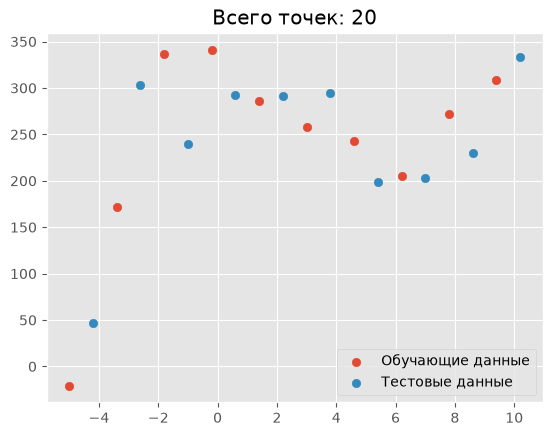

In [2]:
np.random.seed(0)
X = np.arange(-5, 11, 0.8)
y = X**3 - 10 * X**2 + 5 * X + 300 + np.random.normal(0.0, 45, size=X.shape)
plt.scatter(X[::2], y[::2], label='Обучающие данные')
plt.scatter(X[1::2], y[1::2], label='Тестовые данные')
plt.legend()
plt.title(f'Всего точек: {X.shape[0]}')
plt.show()

In [3]:
N = 9
X_N = np.array([[np.random.normal(0.0, 1, size=a.shape) + a ** n for n in range(1, N+1)] for a in X])
X_train = X_N[::2]
X_test = X_N[1::2]
y_train = y[::2]
y_test = y[1::2]

X_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)

X_train, X_test = X_scaler.transform(X_train), X_scaler.transform(X_test)
y_train, y_test = y_scaler.transform(y_train), y_scaler.transform(y_test)
X_N_scaled = X_scaler.transform(X_N)


# Создание линейных моделей

In [4]:
linear = LinearRegression(eta=0.05, n_iter=500)
lasso = Lasso(eta=0.05, n_iter=500, alpha=0.025)
ridge = Ridge(eta=0.05, n_iter=500, alpha=0.03)
elastic = ElasticNet(eta=0.05, n_iter=500, alpha=0.02, l1_ratio=0.5)

models = [
    ('Linear', linear),
    ('Lasso', lasso),
    ('Ridge', ridge),
    ('Elastic', elastic)
]

# Визуализация истории обучения, предсказаний и весов

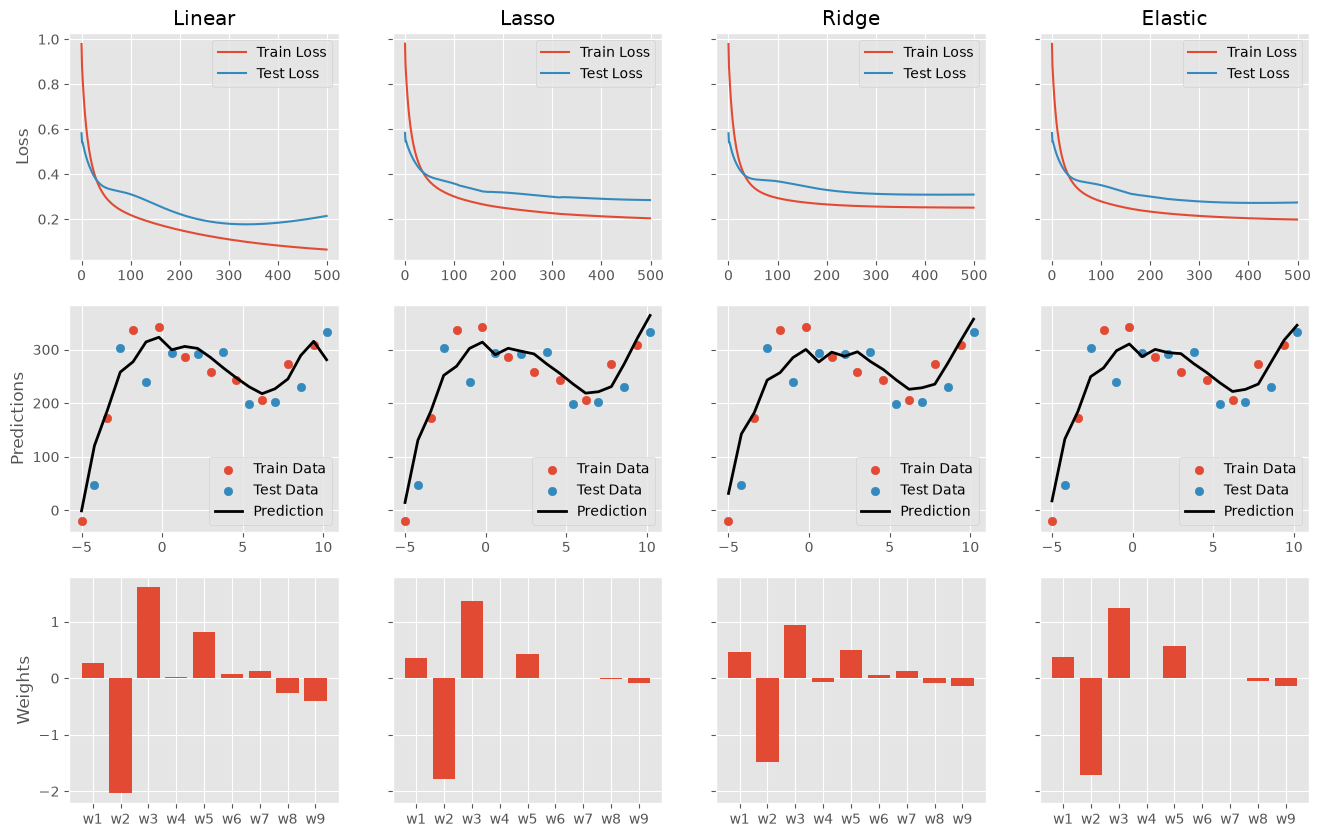

In [5]:
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 10), sharey='row')
weights = [f'w{i}' for i in range(1, N + 1)]

for i, (label, model) in enumerate(models):
    model.fit(X_train, y_train, X_test, y_test)
    axes[0][i].plot(model.losses_, label='Train Loss')
    axes[0][i].plot(model.test_losses_, label='Test Loss')
    axes[0][i].set_title(label)
    axes[0][i].legend()

    axes[1][i].scatter(X[::2], y[::2], label='Train Data')
    axes[1][i].scatter(X[1::2], y[1::2], label='Test Data')
    axes[1][i].plot(X, y_scaler.inverse_transform(model.predict(X_N_scaled)), c='black', lw=2,
                   label='Prediction')
    axes[1][i].legend()
    axes[2][i].bar(x=weights, height=model.w_)
axes[0][0].set_ylabel('Loss')
axes[1][0].set_ylabel('Predictions')
axes[2][0].set_ylabel('Weights')
plt.show()

# Выводы
### 1) **Переобучение:** простая линейная модель без регуляризации более склонна к переобучению, чем остальные. Видно это по стабильному росту ошибки на тестовой выборке и уменьшению на обучающей.
### 2) **Ошибка линейной модели:** вышла меньше чем у остальных. Связано с наличием надбавок (штрафов) у моделей с регуляризацией.
### 3) **Анализ весов:**
* ### **Без регуляризации:** сильный разброс между высотой столбиков. Есть как близкие к нулю, так и большие положительные и отрицательные веса.
* ### **Lasso:** явно виден эффект отбора признаков путём полного зануления некоторых весов.
* ### **Ridge:** некоторые признаки близки к нулю, но нулём не являются. Если сравнить с моделью без регуляризации, то веса вышли более компактными.
* ### **Elastic:** здесь явно видна комбинация L1 и L2 штрафа: веса компактнее, чем у обычной линейной модели, а некоторые из весов в точности равны нулю.